# LAB 8 - DBSCAN Clustering

**Student:** Yash Rajput  &nbsp;|&nbsp;  **Registration No:** 2427010652

Perform **DBSCAN (Density-Based Spatial Clustering of Applications with Noise)** on the public
**Mall Customers** dataset, choose the parameter **eps** with a k-distance graph, detect
**noise/outliers**, and compare the result with K-Means.

## 1. Import libraries, load data and view basic statistics

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["LOKY_MAX_CPU_COUNT"] = "4"
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import DBSCAN, KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

### Load the dataset (online source)

The **Mall Customers** dataset is loaded directly from a public GitHub URL - it contains 200
customers with their annual income and spending score.

In [2]:
url = ("https://raw.githubusercontent.com/SteffiPeTaffy/machineLearningAZ/master/Machine%20Learning%20A-Z%20Template%20Folder/Part%204%20-%20Clustering/Section%2024%20-%20K-Means%20Clustering/Mall_Customers.csv")
df = pd.read_csv(url)

print("Dataset Info:")
print(df.info())
print("\nMissing Values:\n", df.isnull().sum())
df.head()

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None

Missing Values:
 CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


## 2. Select features and visualize the raw data

Clustering is done on **Annual Income** and **Spending Score**, the two features that reveal
customer segments.

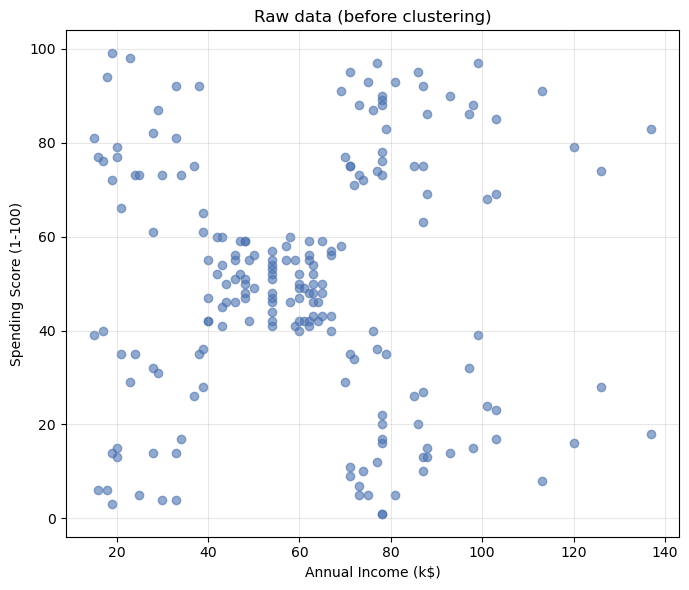

In [4]:
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

plt.figure(figsize=(7, 6))
plt.scatter(X["Annual Income (k$)"], X["Spending Score (1-100)"], alpha=0.6, color="#4C72B0")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Raw data (before clustering)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Scale the data

In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Scaled shape:", X_scaled.shape)

Scaled shape: (200, 2)


## 4. Choose `eps` using the k-distance graph

DBSCAN has two main parameters:
* **eps** - the neighbourhood radius around a point.
* **min_samples** - minimum points needed inside that radius to form a dense region.

We sort every point by the distance to its k-th nearest neighbour (k = min_samples). The sharp
**"knee"** in the plot is a good value for `eps`.

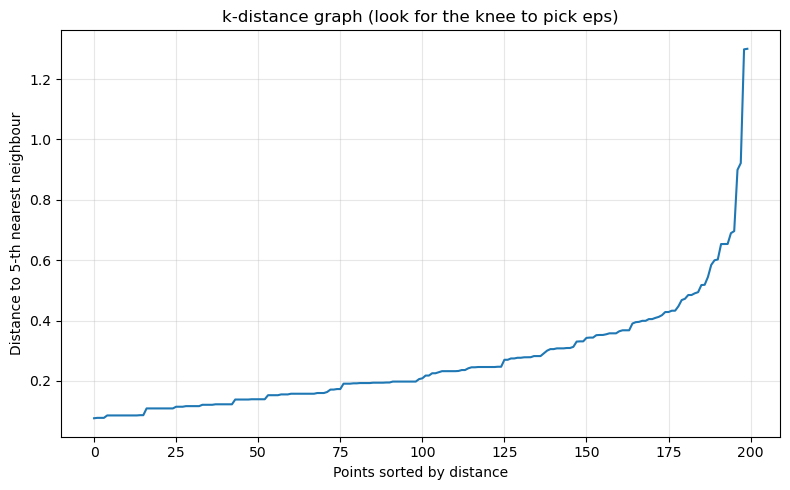

In [6]:
min_samples = 5
neigh = NearestNeighbors(n_neighbors=min_samples)
neigh.fit(X_scaled)
distances, _ = neigh.kneighbors(X_scaled)
k_dist = np.sort(distances[:, -1])

plt.figure(figsize=(8, 5))
plt.plot(k_dist)
plt.xlabel("Points sorted by distance")
plt.ylabel(f"Distance to {min_samples}-th nearest neighbour")
plt.title("k-distance graph (look for the knee to pick eps)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Apply DBSCAN

From the knee above, `eps = 0.4` with `min_samples = 5` works well. Points labelled **-1** are
**noise** (outlier customers that belong to no cluster).

In [7]:
eps = 0.4
dbscan = DBSCAN(eps=eps, min_samples=min_samples)
labels = dbscan.fit_predict(X_scaled)
df["Cluster"] = labels

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)

print("eps =", eps, "| min_samples =", min_samples)
print("Number of clusters found:", n_clusters)
print("Number of noise points:", n_noise)
print("\nPoints per cluster (-1 = noise):")
print(pd.Series(labels).value_counts().sort_index())

eps = 0.4 | min_samples = 5
Number of clusters found: 4
Number of noise points: 15

Points per cluster (-1 = noise):
-1     15
 0    115
 1     11
 2     32
 3     27
Name: count, dtype: int64


In [8]:
mask = labels != -1
if n_clusters > 1:
    score = silhouette_score(X_scaled[mask], labels[mask])
    print("Silhouette Score (excluding noise):", round(score, 3))
else:
    print("Silhouette Score not defined (need >= 2 clusters)")

Silhouette Score (excluding noise): 0.478


### 5.1 Visualize the DBSCAN clusters

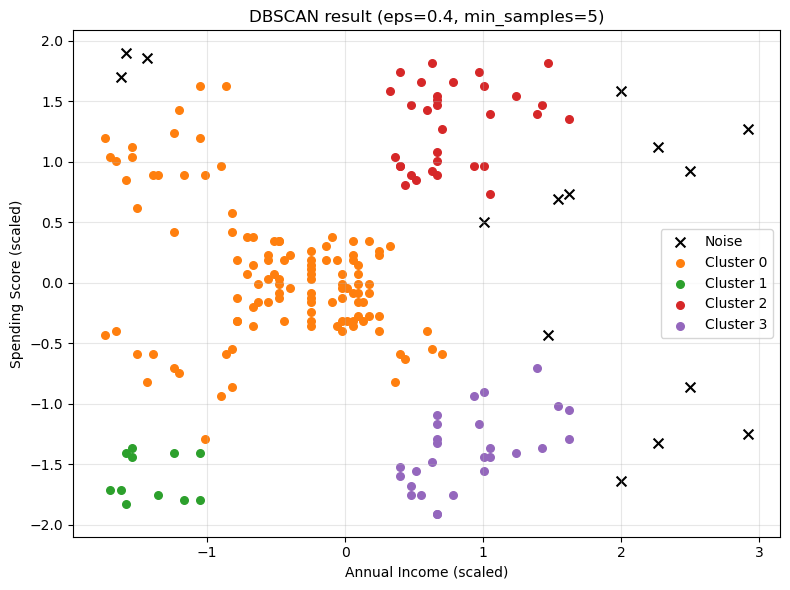

In [9]:
plt.figure(figsize=(8, 6))
unique = sorted(set(labels))
cmap = matplotlib.colormaps["tab10"]

for i, lab in enumerate(unique):
    pts = X_scaled[labels == lab]
    if lab == -1:
        plt.scatter(pts[:, 0], pts[:, 1], c="black", marker="x", s=50, label="Noise")
    else:
        plt.scatter(pts[:, 0], pts[:, 1], color=cmap(i % 10), s=30, label=f"Cluster {lab}")

plt.xlabel("Annual Income (scaled)")
plt.ylabel("Spending Score (scaled)")
plt.title(f"DBSCAN result (eps={eps}, min_samples={min_samples})")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Effect of the `eps` parameter

Small `eps` -> many tiny clusters and lots of noise. Large `eps` -> everything merges into one
cluster. A balanced `eps` gives clean, meaningful customer segments.

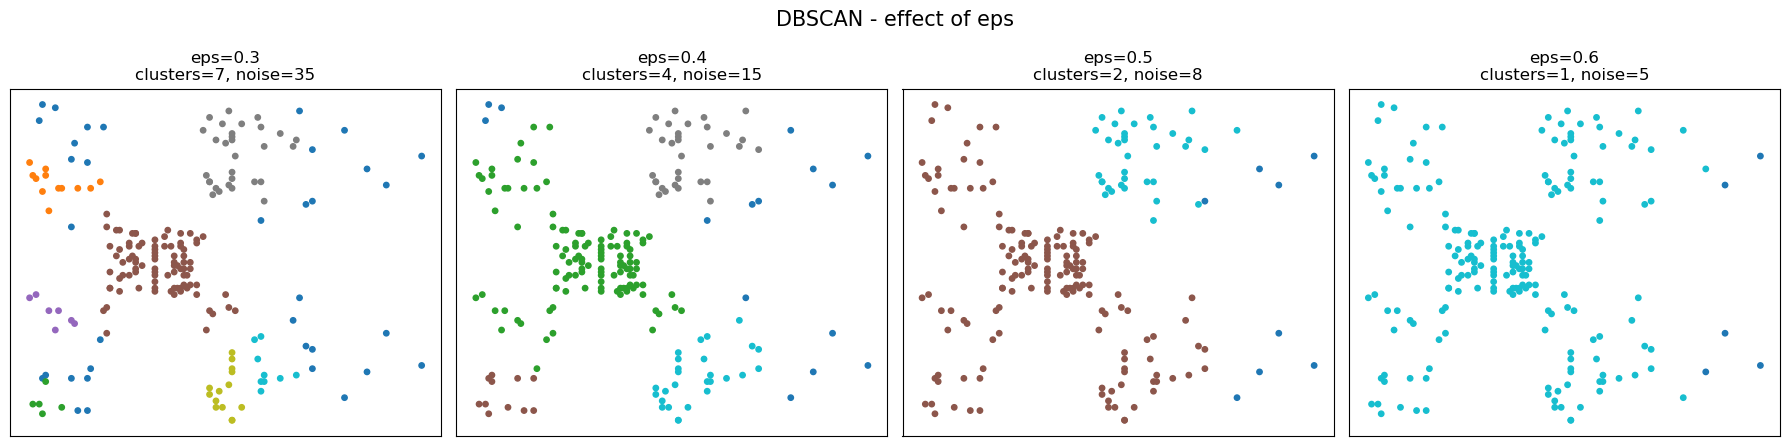

In [10]:
eps_values = [0.3, 0.4, 0.5, 0.6]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

for ax, e in zip(axes, eps_values):
    lab = DBSCAN(eps=e, min_samples=min_samples).fit_predict(X_scaled)
    nc = len(set(lab)) - (1 if -1 in lab else 0)
    nn = list(lab).count(-1)
    ax.scatter(X_scaled[:, 0], X_scaled[:, 1], c=lab, cmap="tab10", s=15)
    ax.set_title(f"eps={e}\nclusters={nc}, noise={nn}")
    ax.set_xticks([]); ax.set_yticks([])

plt.suptitle("DBSCAN - effect of eps", fontsize=15)
plt.tight_layout()
plt.show()

## 7. DBSCAN vs K-Means

K-Means forces **every** point into a cluster (no concept of outliers) and assumes round,
equally sized clusters. DBSCAN follows the data density and separates the genuine **outlier
customers** as noise.

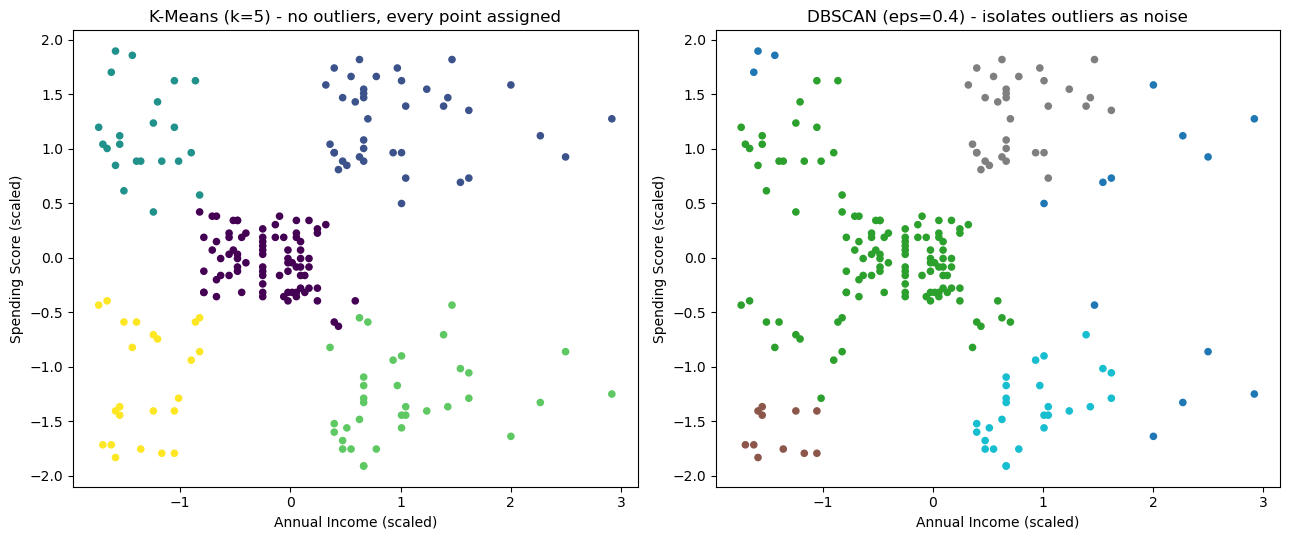

In [11]:
km_labels = KMeans(n_clusters=5, random_state=42, n_init=10).fit_predict(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

axes[0].scatter(X_scaled[:, 0], X_scaled[:, 1], c=km_labels, cmap="viridis", s=20)
axes[0].set_title("K-Means (k=5) - no outliers, every point assigned")

axes[1].scatter(X_scaled[:, 0], X_scaled[:, 1], c=labels, cmap="tab10", s=20)
axes[1].set_title(f"DBSCAN (eps={eps}) - isolates outliers as noise")

for ax in axes:
    ax.set_xlabel("Annual Income (scaled)")
    ax.set_ylabel("Spending Score (scaled)")

plt.tight_layout()
plt.show()